# 国民经济核算 · 逐表数据可视化分析

基于国家统计局「数据库 — 季度数据」（2022Q2 — 2026Q3，共 18 个季度）对**国民经济核算**主题的
6 张数据表逐一进行可视化分析。

| # | 数据表 | 分析内容 |
| --- | --- | --- |
| 1 | 国内生产总值（现价） | 当季柱 + 累计线双轴组合、三次产业堆积 |
| 2 | 国内生产总值（不变价） | 累计面积图 + 当季柱双轴 |
| 3 | 国内生产总值指数 | 总指数与三次产业多线折线（100 基准） |
| 4 | 国内生产总值环比增长速度 | 正负分色柱状图 + 均值线 |
| 5 | 三大需求贡献率 | 当季分组柱状图 + 累计贡献率多线 |
| 6 | 三次产业贡献率 | 100% 堆积柱 + 最新期饼图 |

**口径说明**：现价/不变价增加值为**累计值与当季值**两种口径（亿元）；指数为同比指数
（上年同期 = 100）；环比增速经季节调整；贡献率由统计局发布，之和因四舍五入可能不等于 100%。

In [1]:
# 0 环境与工具函数
import re
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = ['Times New Roman', 'SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.22
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['axes.titlesize'] = 12.5
plt.rcParams['axes.titleweight'] = 'bold'

QMAP = {'一': 1, '二': 2, '三': 3, '四': 4}
DATA_DIR = next(c for c in [Path('data'), Path('国民经济核算/data'), Path('.')]
                if (c / '国内生产总值 (现价).csv').exists())
PAL = ['#0071e3', '#34c759', '#ff9f0a', '#ff375f', '#bf5af2', '#64d2ff', '#ffd60a', '#8e8e93']


def load_table(fname):
    """解析国家统计局季度 CSV，返回 (季度列表[时间正序], {指标名: 数值列表})。缺报按季度轴对齐补 None。"""
    text = (DATA_DIR / fname).read_text(encoding='utf-8-sig')
    quarters, rows = None, {}
    for line in text.splitlines():
        if '\t' not in line:
            continue
        cells = [c.replace(',', '').strip() for c in line.split('\t')]
        first = re.sub(r'\s+', '', cells[0] or '')
        if first == '指标':
            quarters = []
            for c in cells[1:]:
                if not c:
                    continue
                m = re.match(r'(\d{4})年第([一二三四])季度', c)
                if m:
                    quarters.append(f'{m.group(1)}Q{QMAP[m.group(2)]}')
            continue
        if not first or first.startswith(('注', '数据库', '时间', '数据来源')):
            continue
        vals = []
        for c in cells[1:]:
            try:
                vals.append(float(c))
            except ValueError:
                vals.append(None)
        vals = (vals + [None] * len(quarters))[:len(quarters)]  # 按季度轴对齐
        rows[first] = vals
    quarters = list(reversed(quarters))
    rows = {k: list(reversed(v)) for k, v in rows.items()}
    return quarters, rows


def col(rows, prefix):
    key = next((k for k in rows if k.startswith(prefix)), None)
    if key is None:
        raise KeyError(f'未找到指标：{prefix}')
    return rows[key]


def nanify(vals):
    return np.array([np.nan if v is None else v for v in vals], dtype=float)


def short_q(q):
    return q[2:]


print('数据目录：', DATA_DIR.resolve())
print('工具函数加载完成，可逐格运行下方分析。')

数据目录： C:\Users\21409\Desktop\商业数据分析+数据可视化\数据可视化\国家统计局数据可视化分析\国民经济核算\data
工具函数加载完成，可逐格运行下方分析。


## 表 1 · 国内生产总值（现价）

**图 1** 双轴组合图：GDP 当季值（柱）与累计值（线，右轴）；
**图 2** 堆积柱状图：三次产业增加值当季构成。

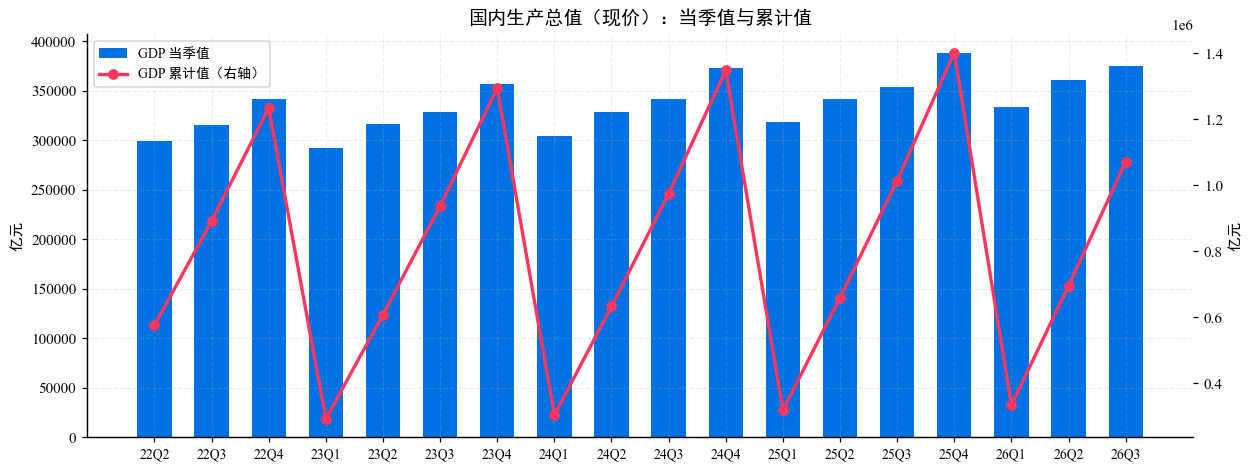

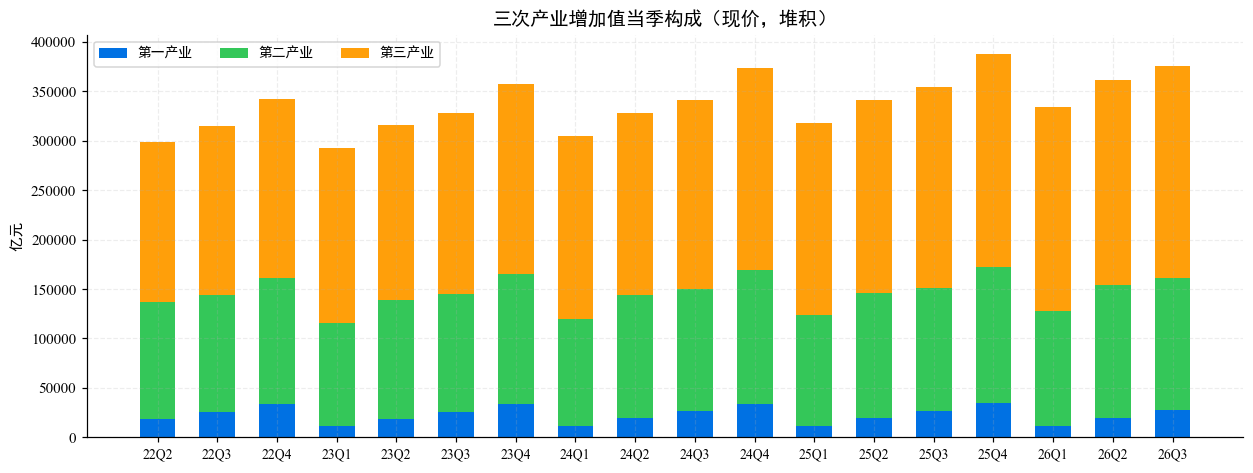

In [2]:
# 表 1：国内生产总值（现价）
quarters, rows = load_table('国内生产总值 (现价).csv')
x = np.arange(len(quarters))
labels = [short_q(q) for q in quarters]

gdp_q = col(rows, '国内生产总值当季值')
gdp_c = col(rows, '国内生产总值累计值')

# 图 1：当季柱 + 累计线（右轴）
fig, ax = plt.subplots(figsize=(11.5, 4.4))
ax.bar(x, gdp_q, 0.6, label='GDP 当季值', color=PAL[0])
ax2 = ax.twinx()
ax2.plot(x, gdp_c, 'o-', color=PAL[3], lw=2.2, label='GDP 累计值（右轴）')
ax2.set_ylabel('亿元')
ax2.grid(False)
ax.set_xticks(x, labels, fontsize=9)
ax.set_ylabel('亿元')
ax.set_title('国内生产总值（现价）：当季值与累计值')
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

# 图 2：三次产业当季堆积柱
p1 = col(rows, '第一产业增加值当季值')
p2 = col(rows, '第二产业增加值当季值')
p3 = col(rows, '第三产业增加值当季值')
fig, ax = plt.subplots(figsize=(11.5, 4.4))
bottom = np.zeros(len(quarters))
for i, (c, vals) in enumerate(zip(['第一产业', '第二产业', '第三产业'], [p1, p2, p3])):
    ax.bar(x, vals, 0.6, bottom=bottom, label=c, color=PAL[i])
    bottom += np.array(vals)
ax.set_xticks(x, labels, fontsize=9)
ax.set_ylabel('亿元')
ax.set_title('三次产业增加值当季构成（现价，堆积）')
ax.legend(ncol=3, loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

## 表 2 · 国内生产总值（不变价）

**图 1** 面积折线图：不变价 GDP 累计值走势（填色面积）+ 当季值（右轴折线）。

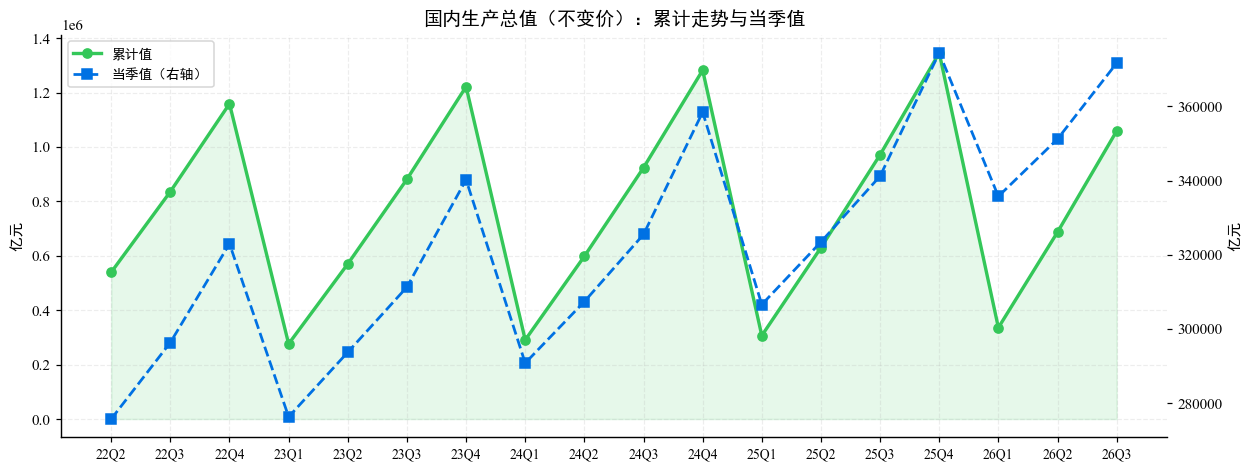

In [3]:
# 表 2：国内生产总值（不变价）
quarters, rows = load_table('国内生产总值 (不变价).csv')
x = np.arange(len(quarters))
labels = [short_q(q) for q in quarters]

gdp_q = nanify(col(rows, '国内生产总值(不变价)当季值'))
gdp_c = nanify(col(rows, '国内生产总值(不变价)累计值'))

fig, ax = plt.subplots(figsize=(11.5, 4.4))
ax.plot(x, gdp_c, 'o-', color=PAL[1], lw=2.2, label='累计值')
ax.fill_between(x, 0, gdp_c, color=PAL[1], alpha=0.12)
ax2 = ax.twinx()
ax2.plot(x, gdp_q, 's--', color=PAL[0], lw=1.8, label='当季值（右轴）')
ax2.set_ylabel('亿元')
ax2.grid(False)
ax.set_xticks(x, labels, fontsize=9)
ax.set_ylabel('亿元')
ax.set_title('国内生产总值（不变价）：累计走势与当季值')
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

## 表 3 · 国内生产总值指数（上年同期=100）

**图 1** 多线折线图：GDP 总指数与三次产业当季指数，红色虚线为 **100 基准**（>100 增长、<100 下降）。

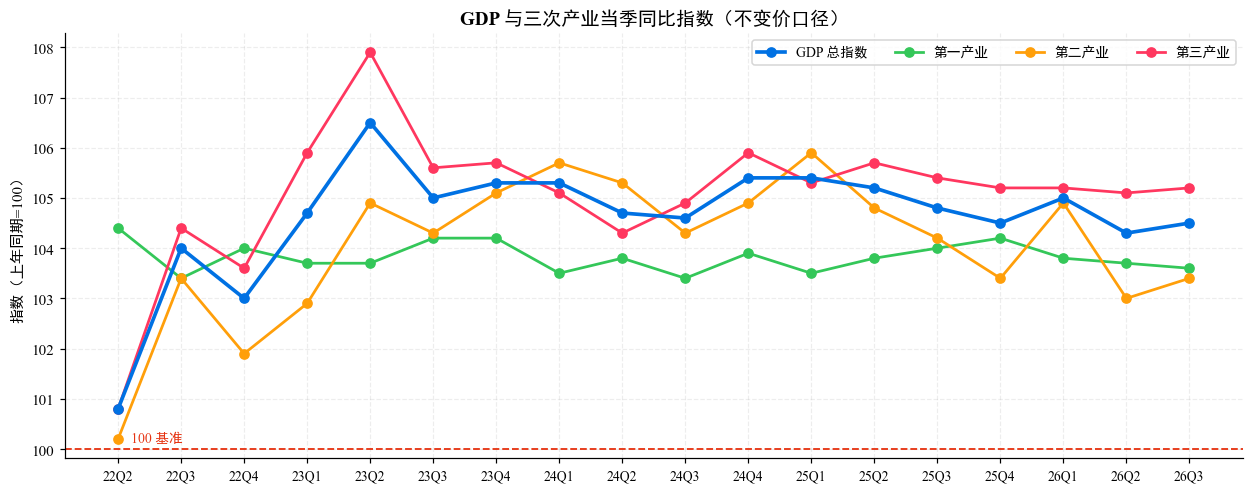

In [4]:
# 表 3：国内生产总值指数
quarters, rows = load_table('国内生产总值指数.csv')
x = np.arange(len(quarters))
labels = [short_q(q) for q in quarters]

series = [
    ('GDP 总指数', nanify(col(rows, '国内生产总值指数(上年同期=100)当季值'))),
    ('第一产业', nanify(col(rows, '第一产业增加值指数(上年同期=100)当季值'))),
    ('第二产业', nanify(col(rows, '第二产业增加值指数(上年同期=100)当季值'))),
    ('第三产业', nanify(col(rows, '第三产业增加值指数(上年同期=100)当季值'))),
]
fig, ax = plt.subplots(figsize=(11.5, 4.6))
for i, (c, vals) in enumerate(series):
    ax.plot(x, vals, 'o-', color=PAL[i], lw=2.4 if i == 0 else 1.8, label=c,
            zorder=5 if i == 0 else 3)
ax.axhline(100, color='#e63312', lw=1.2, ls='--')
ax.text(0.2, 100.15, '100 基准', fontsize=9, color='#e63312')
ax.set_xticks(x, labels, fontsize=9)
ax.set_ylabel('指数（上年同期=100）')
ax.set_title('GDP 与三次产业当季同比指数（不变价口径）')
ax.legend(ncol=4, fontsize=9, loc='upper right')
plt.tight_layout()
plt.show()

## 表 4 · 国内生产总值环比增长速度

**图 1** 柱状图：经季节调整的环比增速（正增长蓝、负增长红），黑色虚线为期间均值。

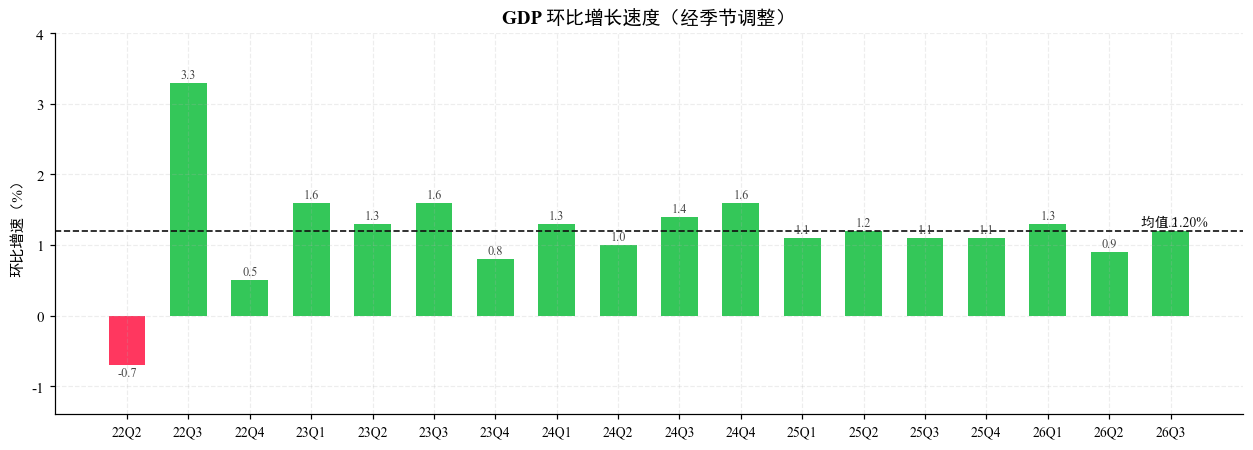

In [5]:
# 表 4：GDP 环比增长速度
quarters, rows = load_table('国内生产总值环比增长速度.csv')
x = np.arange(len(quarters))
labels = [short_q(q) for q in quarters]

qoq = col(rows, '国内生产总值环比增长速度')
mean_v = float(np.mean(qoq))

fig, ax = plt.subplots(figsize=(11.5, 4.2))
bars = ax.bar(x, qoq, 0.6, color=[PAL[1] if v >= 0 else PAL[3] for v in qoq])
for b, v in zip(bars, qoq):
    ax.text(b.get_x() + b.get_width() / 2, v + (0.07 if v >= 0 else -0.16),
            f'{v:.1f}', ha='center', fontsize=8, color='#444444')
ax.axhline(mean_v, color='#111111', lw=1.1, ls='--')
ax.text(len(quarters) - 0.4, mean_v + 0.07, f'均值 {mean_v:.2f}%', ha='right',
        fontsize=9, color='#111111')
ax.set_xticks(x, labels, fontsize=9)
ax.set_ylabel('环比增速（%）')
ax.set_ylim(min(qoq) - 0.7, max(qoq) + 0.7)
ax.set_title('GDP 环比增长速度（经季节调整）')
plt.tight_layout()
plt.show()

## 表 5 · 三大需求对 GDP 增长的贡献率

**图 1** 分组柱状图：最终消费 / 资本形成 / 净出口 **当季**贡献率（可为负，2022Q2 净出口达 170% 为极端值）；
**图 2** 多线折线图：三大需求**累计**贡献率走势。

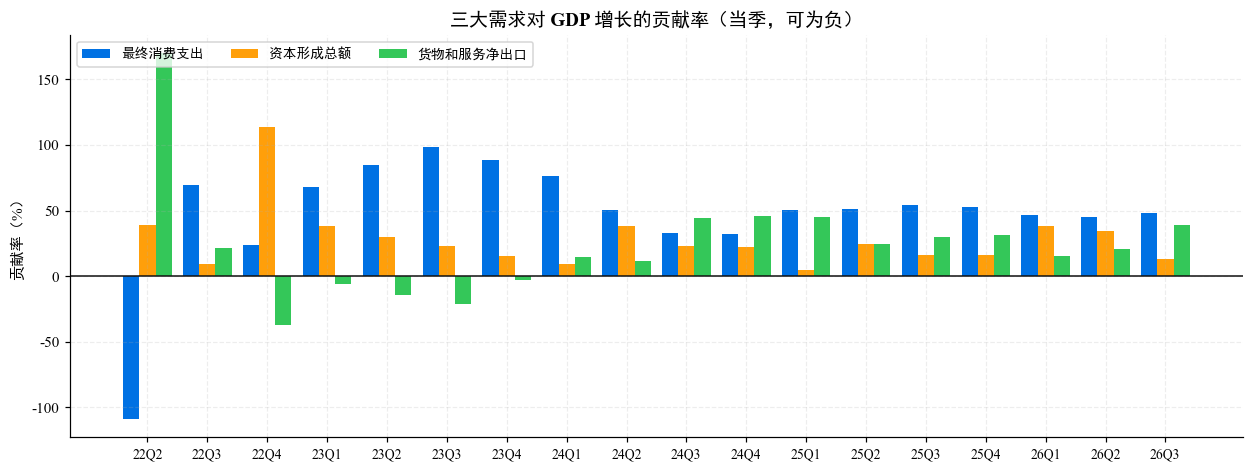

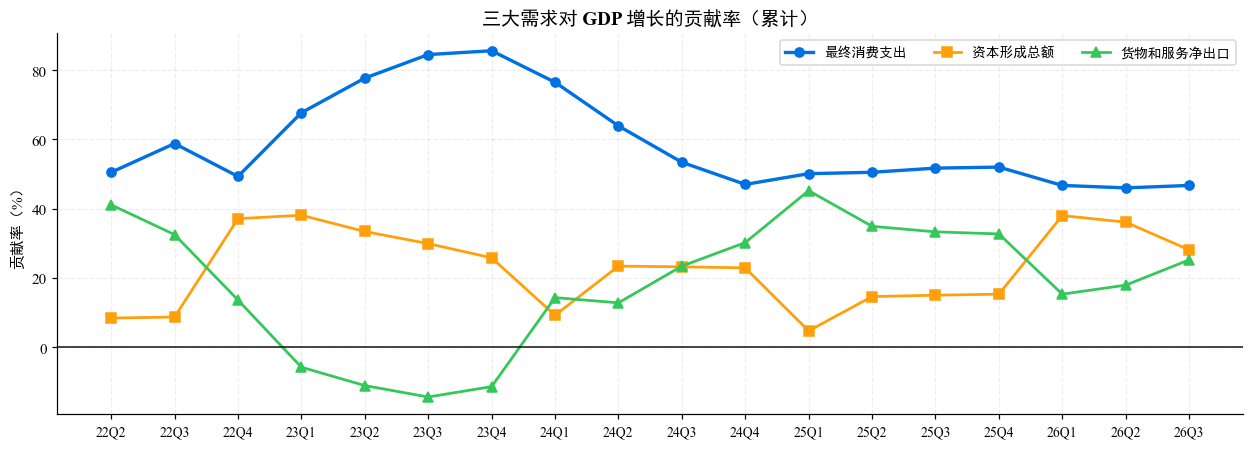

In [6]:
# 表 5：三大需求贡献率
quarters, rows = load_table('三大需求对国内生产总值增长的贡献率.csv')
x = np.arange(len(quarters))
labels = [short_q(q) for q in quarters]

cons = col(rows, '最终消费支出对国内生产总值增长贡献率当季值')
cap = col(rows, '资本形成总额对国内生产总值增长贡献率当季值')
nex = col(rows, '货物和服务净出口对国内生产总值增长贡献率当季值')
cons_c = col(rows, '最终消费支出对国内生产总值增长贡献率累计值')
cap_c = col(rows, '资本形成总额对国内生产总值增长贡献率累计值')
nex_c = col(rows, '货物和服务净出口对国内生产总值增长贡献率累计值')

# 图 1：当季贡献率分组柱状图
w = 0.27
fig, ax = plt.subplots(figsize=(11.5, 4.4))
ax.bar(x - w, cons, w, label='最终消费支出', color=PAL[0])
ax.bar(x, cap, w, label='资本形成总额', color=PAL[2])
ax.bar(x + w, nex, w, label='货物和服务净出口', color=PAL[1])
ax.axhline(0, color='#111111', lw=1)
ax.set_xticks(x, labels, fontsize=9)
ax.set_ylabel('贡献率（%）')
ax.set_title('三大需求对 GDP 增长的贡献率（当季，可为负）')
ax.legend(ncol=3, fontsize=9, loc='upper left')
plt.tight_layout()
plt.show()

# 图 2：累计贡献率多线折线图
fig, ax = plt.subplots(figsize=(11.5, 4.2))
ax.plot(x, cons_c, 'o-', color=PAL[0], lw=2.2, label='最终消费支出')
ax.plot(x, cap_c, 's-', color=PAL[2], lw=1.8, label='资本形成总额')
ax.plot(x, nex_c, '^-', color=PAL[1], lw=1.8, label='货物和服务净出口')
ax.axhline(0, color='#111111', lw=1)
ax.set_xticks(x, labels, fontsize=9)
ax.set_ylabel('贡献率（%）')
ax.set_title('三大需求对 GDP 增长的贡献率（累计）')
ax.legend(ncol=3, fontsize=9, loc='upper right')
plt.tight_layout()
plt.show()

## 表 6 · 三次产业贡献率

**图 1** 100% 堆积柱状图：三次产业**当季**贡献率（合计 100%）；
**图 2** 饼图：最新季度（2026Q3）三次产业贡献占比。

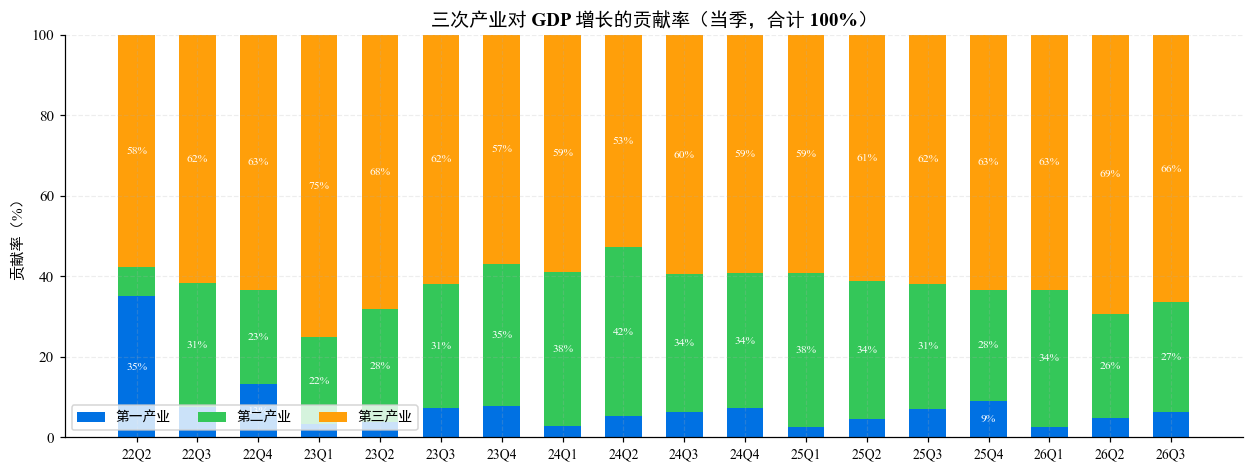

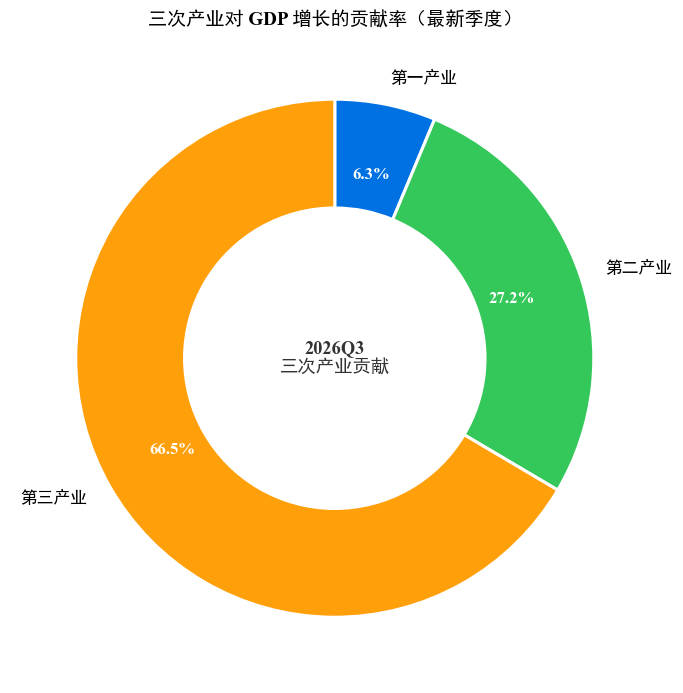

In [7]:
# 表 6：三次产业贡献率
quarters, rows = load_table('三次产业贡献率.csv')
x = np.arange(len(quarters))
labels = [short_q(q) for q in quarters]

pc1 = col(rows, '第一产业贡献率当季值')
pc2 = col(rows, '第二产业贡献率当季值')
pc3 = col(rows, '第三产业贡献率当季值')

# 图 1：100% 堆积柱状图
fig, ax = plt.subplots(figsize=(11.5, 4.4))
bottom = np.zeros(len(quarters))
for i, (c, vals) in enumerate(zip(['第一产业', '第二产业', '第三产业'], [pc1, pc2, pc3])):
    ax.bar(x, vals, 0.6, bottom=bottom, label=c, color=PAL[i])
    for xi, v in enumerate(vals):
        if v >= 8:
            ax.text(xi, bottom[xi] + v / 2, f'{v:.0f}%', ha='center', va='center',
                    fontsize=7.5, color='white')
    bottom += np.array(vals)
ax.set_xticks(x, labels, fontsize=9)
ax.set_ylabel('贡献率（%）')
ax.set_ylim(0, 100)
ax.set_title('三次产业对 GDP 增长的贡献率（当季，合计 100%）')
ax.legend(ncol=3, loc='lower left', fontsize=9)
plt.tight_layout()
plt.show()

# 图 2：最新季度饼图
latest = len(quarters) - 1
vals = [pc1[latest], pc2[latest], pc3[latest]]
fig, ax = plt.subplots(figsize=(7.4, 6.4))
wedges, texts, autotexts = ax.pie(
    vals, labels=['第一产业', '第二产业', '第三产业'], autopct='%1.1f%%', startangle=90,
    counterclock=False, colors=PAL[:3], pctdistance=0.72,
    wedgeprops={'width': 0.42, 'edgecolor': 'white', 'linewidth': 2}, textprops={'fontsize': 11})
for t in autotexts:
    t.set_color('white'); t.set_fontweight('bold')
ax.text(0, 0, f'{quarters[latest]}\n三次产业贡献', ha='center', va='center',
        fontsize=12, fontweight='bold', color='#333333')
ax.set_title('三次产业对 GDP 增长的贡献率（最新季度）')
plt.tight_layout()
plt.show()